# Data Drift

## Feature Drift

Indien de statistische eigenschappen van de *input* data wijzigt, spreken we over feature drift of data drift. Wanneer je bijvoorbeeld in je model de aanname hebt dat data normaal is verdeeld, moet je dit monitoren om te garanderen dat je model goed blijft werken. Er zijn verschillende mogelijke oorzaken van data drift:
- Wijzigingen in het gedrag van gebruikers
- Wijzigingen in databronnen (nieuwe sensors, nieuwe protocollen)
- Verdelingen van data die op 'natuurlijke wijze' veranderen (data met seizoenspatronen, of data die samen de economie fluctureert)
- Wijzigingen in de preprocessing pipeline (wanneer je iets wijzigt aan feature engineering en/of normalisatiestappen, kan dit grote gevolgen hebben in het model)
- Niet-representatieve trainingsdata (bv data getraind op gegevens uit België qua klimaat gaan toepassen in India)
- Slechte data kwaliteit (data gaps, teveel outliers, ...)

Wiskundige notatie: $$ p(X) \neq p(X') $$
De verdeling van de input $X$, tijdens de trainingsfase, blijkt niet meer overeen te komen met de verdeling van de nieuwe inputs  $X'$.

### Feature drift opsporen
Het is belangrijk in een operatieve omgeving om regelmatig controles te doen op de kwaliteit van de inputdata om feature drift op tijd te detecteren. In een MLOps omgeving wordt dit soms gedaan door in een dashboard voortdurend bepaalde metrieken (of ook *KPI's: key performance indicators*) te monitoren.

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Voorbeeld dataset
np.random.seed(42)

# dagelijks data
start_date = datetime(2020, 1, 1)
end_date = datetime(2021, 1, 1)
date_range = pd.date_range(start=start_date, end=end_date, freq='D')

# Random data
data = {
    'Date': date_range,
    'Feature_A': np.random.randn(len(date_range)),
    'Feature_B': np.random.randn(len(date_range)),
    'Feature_C': np.random.randn(len(date_range)),
}

df = pd.DataFrame(data)
current_date = df['Date'].max()

# dataframe historical statistics
historical_data = df[df['Date'] < current_date]
historical_data.set_index('Date', inplace=True)

# dataframe current statistics
current_data = df[df['Date'] == current_date]
current_data.set_index('Date', inplace=True)

In [2]:
# berekening historical statistics
historical_stats_mean = historical_data.mean()
historical_stats_variance = historical_data.var()

# berekening current statistics
current_stats_mean = current_data.mean()
current_stats_variance = current_data.var()

# print resultaten
print("Historical Statistics:")
print(historical_stats_mean, historical_stats_variance)

print("\nCurrent Statistics:")
print(current_stats_mean, current_stats_variance)

Historical Statistics:
Feature_A    0.008823
Feature_B   -0.038449
Feature_C    0.130249
dtype: float64 Feature_A    0.896800
Feature_B    1.038986
Feature_C    0.914922
dtype: float64

Current Statistics:
Feature_A    0.224092
Feature_B   -1.702584
Feature_C    0.998010
dtype: float64 Feature_A   NaN
Feature_B   NaN
Feature_C   NaN
dtype: float64


In [ ]:
type(historical_stats_mean[0])

In een operationele setup zou je voor elk van die waardes een alarmdrempel hebben, zodat je kan ingrijpen indien nodig. Pas de volgende code aan zodat dit werkt:

In [ ]:
# we kijken naar de eerste variabele (index 0)
variable_index = 0

# tresholds (alarmwaardes)
#TODO

# bekijk het verschil
#TODO

# Geef een Warning als er drift is opgetreden.
#TODO

### Oefening

Pas de code aan zodat er in het huidige frame gekeken wordt naar de laatste 7 dagen aan data. Bepaal aan de hand van de summary statistics van het dataframe (`.describe()`) wat een goede threshold zou zijn om mee te starten.

In [ ]:
#TODO

Je kan ook een Kolmogorov_Smirnov test uitvoeren om te checken of de data significant verschillend is. Hier komt dan een *p*-waarde uit, als die lager is dan een threshold (standaard is die threshold 0.05), dan heb je effectief een verschil en dus feature drift.

In [ ]:
#TODO

### Machine learning drift detectie
Je kan ook machine learning gebruiken om automatisch drift te detecteren.

In [ ]:
import numpy as np
from scipy.stats import ks_2samp


class DriftDetector:
    def __init__(self, significance_level=0.05):
        self.significance_level = significance_level
        self.reference_data = None
   
    def fit(self, reference_data):
        self.reference_data = reference_data
   
    def detect_drift(self, new_data):
        #TODO, geeft een boolean value terug

# Voorbeeld
reference_data = np.random.normal(loc=0, scale=1, size=1000)
new_data = np.random.normal(loc=0.2, scale=1, size=1000)

# Initializeer de detector
drift_detector = DriftDetector(significance_level=0.05)
drift_detector.fit(reference_data)

# Februik de detector
is_drift_detected = drift_detector.detect_drift(new_data)
print("Drift detected:", is_drift_detected)

### Feature drift oplossen
Als je feature drift hebt vastgesteld, zijn er verschillende manieren om hiermee om te gaan
Er zijn verschillende technieken:
1. **Opnieuw trainen met relevante data** De nieuwe datapunten op een gewogen manier meenemen in de trainingsdata om de input verdeling beter te weerspiegelen. Hier ga je eigenlijk een nieuwe, gebalanceerde dataset creëren en je model **opnieuw trainen**.
2. **Domein adaptatie technieken**: het model aan de outputkant aanpassen, door het model een mapping te leren tussen de *oude outputwaarden* en de *nieuwe outputwaarden*.

## Concept Drift

Bij concept drift (ook wel *class drift*) verandert de relatie tussen de input en de output van de gegevens. Dit wordt ook wel *model drift* genoemd. Bij concept drift zijn er bepaalde aannames, die nodig zijn om een model te gebruiken, niet meer geldig, waardoor het model voorspellingen begint te geven die afwijken van de realiteit. Opnieuw zijn er veel mogelijke oorzaken:
- veranderende voorkeuren van gebruikers (denk aan opgroeiende jongeren, en dus wijzigende smaak, met een account op een platform recommender system)
- wijziging in externe factoren (bijvoorbeeld een wijziging in wetgeving waardoor bepaalde labels niet meer kloppen)
- data die cyclische patronen vertoont (seizoenen en of volgen van economische of andere patronen)
- Externe factoren (onverwachte omstandigheden, denk aan COVID19)

Wiskundige notatie: $$ p_1(y|X) \neq p_2(y|X) $$
De kansverdeling is hier in de twee situaties fundamenteel verschillend. Hierdoor zijn bepaalde labels in het ene model niet meer juist in het andere model. In vroege spammodellen werk elke mass mailing als spam aangeduid, maar vandaag zijn er veel newsletters waar mensen bewust op intekenen. Dus het nieuwe spammodel moet exact dezelfde input nu een ander label geven. De context rond het model is gewijzigd.

### Detectie van concept drift

Concept drift kun je detecteren met het **Adwin-algoritme**. Dit ADaptive WINdowing algoritme houdt statistieken bij in een 'sliding window', dus een periode in de tijd die telkens de laatste metingen selecteert.

Installatie: `pip install -U scikit-multiflow`. Indien dit niet lukt: code is ter illustratie.

In [1]:
# https://scikit-multiflow.readthedocs.io/en/stable/api/generated/skmultiflow.drift_detection.ADWIN.html

import numpy as np
from skmultiflow.drift_detection.adwin import ADWIN
adwin = ADWIN()
# Simulating a data stream as a normal distribution of 1's and 0's
data_stream = np.random.randint(2, size=2000)
# Changing the data concept from index 999 to 2000
for i in range(999, 2000):
    data_stream[i] = np.random.randint(4, high=8)
# Adding stream elements to ADWIN and verifying if drift occurred
for i in range(2000):
    adwin.add_element(data_stream[i])
    if adwin.detected_change():
        print('Change detected in data: ' + str(data_stream[i]) + ' - at index: ' + str(i))

ModuleNotFoundError: No module named 'skmultiflow'

## Het verschil tussen feature drift en concept drift
Bij feature drift gaat de *decision boundary*, de grenzen van bepaalde labels, niet wijzigen. Het enige wat wijzigt is de statistische verdeling van de *inputs*. Bij concept drift gaat de decision boundary wél wijzigen, hetzij bewust, hetzij onbewust, maar altijd als gevolg van een gewijzigde situatie in de *echte wereld*.

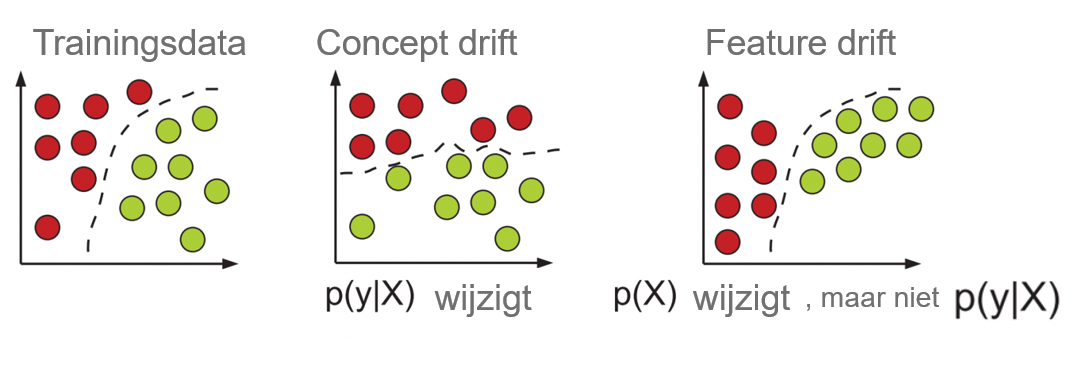